# LSTM forecast of PM2.5 with 95% confidence intervals
Extended with inhaled dose & classification logic (health indicators and messages).

**Data:** `PM2_5.xlsx` (columns: `Date`, `PM2.5`)

Python translation of `lstm_pm2_5_ci_pr3_dose_1026.R`.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)  # seeds python, numpy and tensorflow

## 1. Load & prepare data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Modifiez le chemin ci-dessous selon l'emplacement exact de votre fichier dans Google Drive
# Par exemple, s'il est à la racine de votre Drive :
file_path = '/content/drive/MyDrive/PM2_5.xlsx'

Mounted at /content/drive


In [3]:
file_path = "/content/drive/MyDrive/LSTM_model_PM2_5_JOJ/PM2_5.xlsx"

df = pd.read_excel(file_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

values = df["PM2.5"].to_numpy(dtype="float64")
min_val = values.min()
max_val = values.max()
scaled = (values - min_val) / (max_val - min_val)

look_back = 30


def create_sequences(data, look_back):
    n = len(data) - look_back
    X = np.empty((n, look_back))
    y = np.empty(n)
    for i in range(n):
        X[i, :] = data[i:i + look_back]
        y[i] = data[i + look_back]
    return X, y


X, y = create_sequences(scaled, look_back)
X = X.reshape(X.shape[0], look_back, 1)

split_idx = int(np.floor(X.shape[0] * 0.85))
X_train = X[:split_idx]
y_train = y[:split_idx]

## 2. Build & train the LSTM

In [4]:
dropout_rate = 0.2

model = keras.Sequential([
    keras.Input(shape=(look_back, 1)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(dropout_rate),
    layers.LSTM(32),
    layers.Dropout(dropout_rate),
    layers.Dense(16, activation="relu"),
    layers.Dense(1),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

# NB: like R's validation_split, Keras takes the LAST 15% of X_train for validation
history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=150,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.0027 - mae: 0.0295 - val_loss: 1.9725e-04 - val_mae: 0.0084
Epoch 2/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0021 - mae: 0.0205 - val_loss: 2.0217e-04 - val_mae: 0.0072
Epoch 3/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0021 - mae: 0.0208 - val_loss: 2.0225e-04 - val_mae: 0.0072
Epoch 4/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0021 - mae: 0.0205 - val_loss: 1.9876e-04 - val_mae: 0.0078
Epoch 5/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0021 - mae: 0.0195 - val_loss: 2.0414e-04 - val_mae: 0.0075
Epoch 6/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0021 - mae: 0.0202 - val_loss: 1.9705e-04 - val_mae: 0.0076
Epoch 7/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0020 - mae: 0.0188 - val_loss: 2.1157e-04 - val_mae: 0.0092
Epoch 8/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0021 - mae: 0.0201 - val_loss: 2.0305e-04 - val_mae: 0.0082
Epoch 9/150
28/28 ━━━━━━

## 3. Monte Carlo Dropout forecast for the next 2 days

In [5]:
n_days = 2
n_simulations = 500

last_window = scaled[-look_back:].reshape(1, look_back, 1).astype("float32")
sim_paths = np.full((n_simulations, n_days), np.nan)

for s in range(n_simulations):
    window = last_window.copy()
    for d in range(n_days):
        next_val = float(model(window, training=True).numpy().ravel()[0])  # dropout ON
        sim_paths[s, d] = next_val
        window = np.concatenate(
            [window[0, 1:, 0], [next_val]]
        ).reshape(1, look_back, 1).astype("float32")


def inverse_scale(x):
    return x * (max_val - min_val) + min_val


sim_paths_inv = inverse_scale(sim_paths)

mean_forecast = sim_paths_inv.mean(axis=0)
sd_forecast = sim_paths_inv.std(axis=0, ddof=1)             # R's sd() uses n-1
lower_ci = np.quantile(sim_paths_inv, 0.025, axis=0)         # same as R's type 7
upper_ci = np.quantile(sim_paths_inv, 0.975, axis=0)

future_dates = pd.date_range(df["Date"].max() + pd.Timedelta(days=1),
                             periods=n_days, freq="D")

forecast_ci_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast": mean_forecast,
    "SD": sd_forecast,
    "Lower_95": lower_ci,
    "Upper_95": upper_ci,
})

print("\n2-day forecast with 95% CI (Monte Carlo Dropout):")
print(forecast_ci_df.to_string(index=False))
forecast_ci_df.to_csv("PM2.5_2day_forecast_CI_py.csv", index=False)


2-day forecast with 95% CI (Monte Carlo Dropout):
      Date  Forecast       SD  Lower_95  Upper_95
2026-06-07 34.002805 2.064885 29.967781 38.020612
2026-06-08 34.379915 2.058434 30.207889 37.954096


## 4. PM2.5 classification (J+1, J+2)
Applied to `Forecast`, `Lower_95` and `Upper_95`.

In [6]:
def classify_pm25(x):
    # Continuous cut-offs so no value falls between the document's integer bands
    if pd.isna(x) or x <= 0:
        return None  # the document only defines 0 < Forecast
    if x <= 15:
        return "Aucune restriction majeure"
    if x <= 40:
        return "Qualité acceptable pour la population générale"
    if x <= 65:
        return "Risque modéré pour les personnes sensibles (asthme, enfants)."
    return "Alerte générale. Éviter les activités physiques intenses en extérieur."


forecast_ci_df.insert(0, "Day", [f"J+{i + 1}" for i in range(len(forecast_ci_df))])
forecast_ci_df["Class_Forecast"] = forecast_ci_df["Forecast"].apply(classify_pm25)
forecast_ci_df["Class_Lower_95"] = forecast_ci_df["Lower_95"].apply(classify_pm25)
forecast_ci_df["Class_Upper_95"] = forecast_ci_df["Upper_95"].apply(classify_pm25)

## 5. Health indicators: hospital admissions (RR, attributable fraction)
- `beta   = ln(RRunit) / 10` (RR is per 10 µg/m³)
- `RRobs  = exp(beta * (Forecast - 15))` (counterfactual = WHO daily guideline, 15 µg/m³)
- `FA     = (RRobs - 1) / RRobs`

In [7]:
counterfactual = 15   #  (ug/m3)
sn_reference = 65     # Senegalese regulatory benchmark (ug/m3)

# RRunit and its 95% CI, per 10 ug/m3 of PM2.5
rr_table = pd.DataFrame({
    "Outcome": ["cardiovasculaires", "respiratoires"],
    "ICD10":   ["I00-I99", "J00-J99"],
    "RR_unit": [1.0090, 1.0057],
    "RR_low":  [1.0026, 1.0033],
    "RR_high": [1.0153, 1.0082],
})


def calc_rr_fa(forecast, rr_unit):
    beta = np.log(rr_unit) / 10
    excess = max(forecast - counterfactual, 0)  # no excess risk at or below 15
    rr_obs = np.exp(beta * excess)
    fa = (rr_obs - 1) / rr_obs
    return {"RR_obs": rr_obs, "FA": fa}


health_rows = []
for d in range(len(forecast_ci_df)):
    for o in range(len(rr_table)):
        fc = forecast_ci_df["Forecast"].iloc[d]
        est = calc_rr_fa(fc, rr_table["RR_unit"].iloc[o])
        lo = calc_rr_fa(fc, rr_table["RR_low"].iloc[o])
        hi = calc_rr_fa(fc, rr_table["RR_high"].iloc[o])
        health_rows.append({
            "Day": forecast_ci_df["Day"].iloc[d],
            "Date": forecast_ci_df["Date"].iloc[d],
            "Forecast": fc,
            "Outcome": rr_table["Outcome"].iloc[o],
            "ICD10": rr_table["ICD10"].iloc[o],
            "RR_unit": rr_table["RR_unit"].iloc[o],
            "RR_obs": est["RR_obs"],
            "RR_obs_low": lo["RR_obs"],    # from the lower bound of RRunit
            "RR_obs_high": hi["RR_obs"],   # from the upper bound of RRunit
            "FA_pct": 100 * est["FA"],
            "FA_pct_low": 100 * lo["FA"],
            "FA_pct_high": 100 * hi["FA"],
        })
health_df = pd.DataFrame(health_rows)

## 6. Message (one single message per day: cardiovascular + respiratory)
Only produced when Forecast > 15 µg/m³ (WHO daily guideline = counterfactual).
- X, Y = excess relative risk in % = `(RRobs - 1) * 100` (cardiovascular, respiratory)
- A, B = attributable fraction in % (cardiovascular, respiratory)

In [9]:
def fr(x, d=2):
    """Format with a French decimal comma."""
    return f"{x:.{d}f}".replace(".", ",")


def make_message(forecast, cv, resp):
    """cv / resp: rows of health_df for cardiovascular / respiratory outcomes (same day)."""
    x = 100 * (cv["RR_obs"] - 1)      # % higher risk, cardiovascular
    y = 100 * (resp["RR_obs"] - 1)    # % higher risk, respiratory
    return (
        f"PM2,5 prévu : {fr(forecast, 1)} µg/m³. Cette concentration est supérieure à la valeur "
        f"guide journalière de l’OMS, fixée à {counterfactual:d} µg/m³. Par rapport à ce niveau de "
        f"référence, le risque d’hospitalisation pour causes cardiovasculaires est estimé "
        f"{fr(x)} % plus élevé, et celui pour causes respiratoires {fr(y)} % plus élevé. "
        f"La fraction attribuable est estimée respectivement à {fr(cv['FA_pct'])} % et "
        f"{fr(resp['FA_pct'])} %. Elle représente, la part du risque "
        f"d’hospitalisation estimé à cette concentration qui est attribuable à l’exposition aux "
        f"PM2,5 au-dessus du niveau de référence de {counterfactual:d} µg/m³."
    )


message_rows = []
for day, g in health_df.groupby("Day", sort=False):
    cv = g[g["Outcome"] == "cardiovasculaires"].iloc[0]
    resp = g[g["Outcome"] == "respiratoires"].iloc[0]
    fc = cv["Forecast"]
    message_rows.append({
        "Day": day,
        "Date": cv["Date"],
        "Forecast": fc,
        "Message": make_message(fc, cv, resp) if fc > counterfactual else None,
    })
messages_df = pd.DataFrame(message_rows)

print("\nClassification of forecast concentrations:")
print(forecast_ci_df[["Day", "Date", "Forecast", "Lower_95", "Upper_95",
                      "Class_Forecast"]].to_string(index=False))

print("\nRR and attributable fraction:")
print(health_df[["Day", "Outcome", "Forecast", "RR_obs", "FA_pct"]].to_string(index=False))

print("\nMessages:")
for _, row in messages_df.iterrows():
    print(f"\n[{row['Day']}]")
    print(row["Message"] if pd.notna(row["Message"])
          else f"Pas de message : PM2,5 prévu <= {counterfactual} µg/m³ (valeur guide OMS).")



Classification of forecast concentrations:
Day       Date  Forecast  Lower_95  Upper_95                                 Class_Forecast
J+1 2026-06-07 34.002805 29.967781 38.020612 Qualité acceptable pour la population générale
J+2 2026-06-08 34.379915 30.207889 37.954096 Qualité acceptable pour la population générale

RR and attributable fraction:
Day           Outcome  Forecast   RR_obs   FA_pct
J+1 cardiovasculaires 34.002805 1.017172 1.688190
J+1     respiratoires 34.002805 1.010859 1.074273
J+2 cardiovasculaires 34.379915 1.017516 1.721402
J+2     respiratoires 34.379915 1.011076 1.095474

Messages:

[J+1]
PM2,5 prévu : 34,0 µg/m³. Cette concentration est supérieure à la valeur guide journalière de l’OMS, fixée à 15 µg/m³. Par rapport à ce niveau de référence, le risque d’hospitalisation pour causes cardiovasculaires est estimé 1,72 % plus élevé, et celui pour causes respiratoires 1,09 % plus élevé. La fraction attribuable est estimée respectivement à 1,69 % et 1,07 %. Elle représ

## 7. Save results

In [10]:
forecast_ci_df.to_csv("PM2.5_2day_forecast_CI_py.csv", index=False, encoding="utf-8")

with pd.ExcelWriter("PM2.5_2day_forecast_health_py.xlsx") as writer:  # needs openpyxl
    forecast_ci_df.to_excel(writer, sheet_name="Forecast_Classification", index=False)
    health_df.to_excel(writer, sheet_name="Health_Indicators", index=False)
    messages_df.to_excel(writer, sheet_name="Messages", index=False)


## (Optional) Plot: recent history + forecast with 95% CI
The R script loaded `ggplot2` but did not draw a plot; this cell is an optional addition.

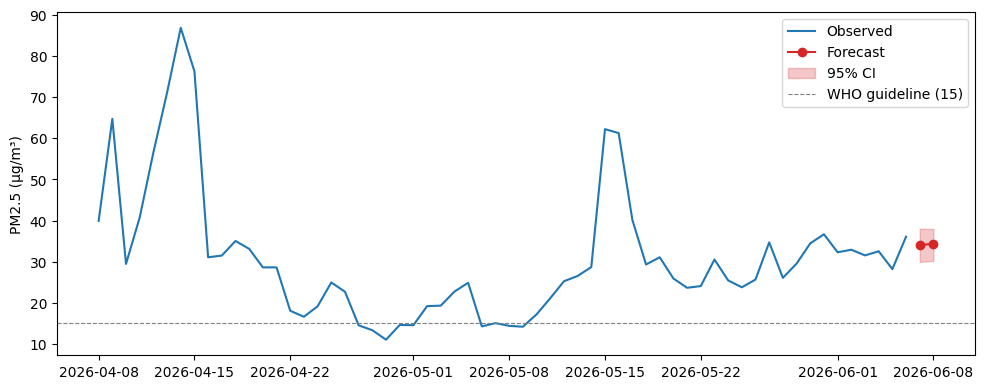

In [11]:
recent = df.tail(60)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(recent["Date"], recent["PM2.5"], label="Observed")
ax.plot(forecast_ci_df["Date"], forecast_ci_df["Forecast"], "o-", color="tab:red", label="Forecast")
ax.fill_between(forecast_ci_df["Date"], forecast_ci_df["Lower_95"],
                forecast_ci_df["Upper_95"], color="tab:red", alpha=0.25, label="95% CI")
ax.axhline(counterfactual, ls="--", color="gray", lw=0.8, label="WHO guideline (15)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.show()